In [1]:
'''Convert trained machine learning models into optimized and secure serialized formats (pickle/joblib/ONNX), 
ensuring compatibility across different platforms and environments for seamless deployment.'''

'Convert trained machine learning models into optimized and secure serialized formats (pickle/joblib/ONNX), \nensuring compatibility across different platforms and environments for seamless deployment.'

In [2]:
# importing required libraries
import os
import pickle
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from skl2onnx import to_onnx
import onnxruntime as ort

In [3]:
# loading dataset
df = pd.read_csv('global_pharmacy_sales_data.csv')
df.head()

,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


In [4]:
# inspecting dataset information
print(df.shape)
print(df.columns.tolist())

(177990, 14)
['date', 'year', 'month', 'day', 'region', 'country', 'category', 'medicine', 'age_group', 'units_sold', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']


In [5]:
# preparing features and target classification variable
df['high_sales'] = (df['units_sold'] >= df['units_sold'].median()).astype(int)
features = ['unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag', 'month']
sample_df = df.sample(n=5000, random_state=42).reset_index(drop=True)
X = sample_df[features].values.astype(np.float32)
y = sample_df['high_sales'].values
print('features shape:', X.shape)
print('target distribution:\n', pd.Series(y).value_counts())

features shape: (5000, 5)
target distribution:
 1    2501
0    2499
Name: count, dtype: int64


In [6]:
# splitting dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(4000, 5) (1000, 5)


In [7]:
# training machine learning model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('model test accuracy:', accuracy_score(y_test, y_pred))

model test accuracy: 0.839


In [8]:
# serializing model using pickle format
with open('pharmacy_model.pkl', 'wb') as f:
    pickle.dump(model, f)
print('pickle model serialized successfully')

pickle model serialized successfully


In [9]:
# serializing model using joblib format
joblib.dump(model, 'pharmacy_model.joblib')
print('joblib model serialized successfully')

joblib model serialized successfully


In [10]:
# converting and serializing model to onnx format
onnx_model = to_onnx(model, X_train[:1])
with open('pharmacy_model.onnx', 'wb') as f:
    f.write(onnx_model.SerializeToString())
print('onnx model converted and serialized successfully')

onnx model converted and serialized successfully


In [11]:
# loading models and verifying predictions across all formats
with open('pharmacy_model.pkl', 'rb') as f:
    loaded_pickle = pickle.load(f)
loaded_joblib = joblib.load('pharmacy_model.joblib')
loaded_onnx_sess = ort.InferenceSession('pharmacy_model.onnx')
onnx_input_name = loaded_onnx_sess.get_inputs()[0].name

test_sample = X_test[:5]
pred_original = model.predict(test_sample)
pred_pickle = loaded_pickle.predict(test_sample)
pred_joblib = loaded_joblib.predict(test_sample)
pred_onnx = loaded_onnx_sess.run(None, {onnx_input_name: test_sample})[0]

print('original model predictions:', pred_original)
print('pickle model predictions:  ', pred_pickle)
print('joblib model predictions:  ', pred_joblib)
print('onnx model predictions:    ', pred_onnx)
print('all serialized predictions match:', np.array_equal(pred_original, pred_pickle) and np.array_equal(pred_original, pred_onnx))

original model predictions: [1 0 0 1 0]
pickle model predictions:   [1 0 0 1 0]
joblib model predictions:   [1 0 0 1 0]
onnx model predictions:     [1 0 0 1 0]
all serialized predictions match: True


In [12]:
# comparing file sizes of serialized models
size_pickle = os.path.getsize('pharmacy_model.pkl')
size_joblib = os.path.getsize('pharmacy_model.joblib')
size_onnx = os.path.getsize('pharmacy_model.onnx')

size_df = pd.DataFrame({
    'format': ['pickle', 'joblib', 'onnx'],
    'size_bytes': [size_pickle, size_joblib, size_onnx]
})
print(size_df)

   format  size_bytes
0  pickle         756
1  joblib         911
2    onnx         559


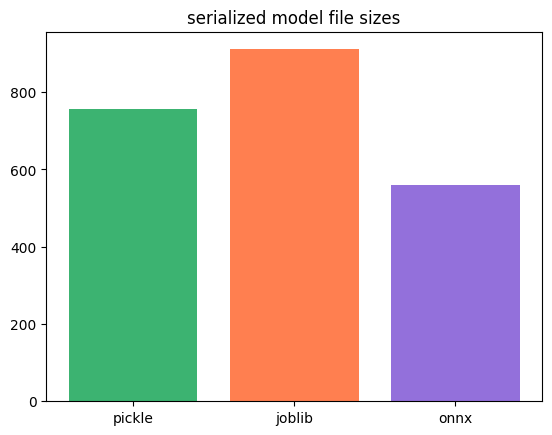

In [13]:
# plotting serialized model file sizes
plt.bar(['pickle', 'joblib', 'onnx'], [size_pickle, size_joblib, size_onnx], color=['mediumseagreen', 'coral', 'mediumpurple'])
plt.title('serialized model file sizes')
plt.show()